# Session 23 Solutions: Project 3: Your First ML Model

Data Science with Python, Level 1, Stage 3: Statistics and ML Fundamentals

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.metrics import roc_auc_score, recall_score, precision_score, confusion_matrix

DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
churn = pd.read_csv(DATA_URL + "telecom_churn.csv")
y = (churn["churn"] == "Yes").astype(int)

## In-Class Exercises

### In-Class Exercise 1: Frame the Problem

In [2]:
framing = '''
Target: churn (1 = the customer leaves).
Decision: which customers the retention team calls each month.
Main metric: recall at a fixed call budget, with ROC AUC for ranking quality.
False negative: a lost customer, about 12 months of charges.
False positive: one unnecessary call and a small discount.
'''
print(framing)


Target: churn (1 = the customer leaves).
Decision: which customers the retention team calls each month.
Main metric: recall at a fixed call budget, with ROC AUC for ranking quality.
False negative: a lost customer, about 12 months of charges.
False positive: one unnecessary call and a small discount.



### In-Class Exercise 2: Missing Values

In [3]:
print(churn.isna().sum()[churn.isna().sum() > 0])
print(churn.loc[churn["total_charges"].isna(), ["tenure_months", "monthly_charges", "total_charges"]].head())
# internet: missing means the customer has no internet service, so fill with "None".
# total_charges: a few gaps in customers with normal tenure, so rebuild it as tenure times monthly charges.

internet         400
total_charges     11
dtype: int64
     tenure_months  monthly_charges  total_charges
213             21            25.32            NaN
328             39            73.08            NaN
587              3            81.00            NaN
588             24            97.44            NaN
668              1            18.00            NaN


### In-Class Exercise 3: Call List

In [4]:
def prepare(df):
    out = df.drop(columns=["customer_id", "churn"]).copy()
    out["internet"] = out["internet"].fillna("None")
    out["total_charges"] = out["total_charges"].fillna(out["tenure_months"] * out["monthly_charges"])
    out["male"] = (out.pop("gender") == "Male").astype(int)
    out = pd.get_dummies(out, columns=["contract", "internet", "payment_method"], drop_first=True)
    return out.astype(float)

X = prepare(churn)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_dev, y_dev)
risk = pd.Series(model.predict_proba(X_test)[:, 1], index=X_test.index, name="risk")
calls = churn.loc[X_test.index, ["contract", "tenure_months", "monthly_charges"]].assign(risk=risk, left=y_test).nlargest(10, "risk")
print(calls.round(2))
print("Left:", calls["left"].sum(), "of 10")

            contract  tenure_months  monthly_charges  risk  left
1816  Month-to-month              9            80.42  0.91     1
595   Month-to-month             11           100.15  0.90     1
1451  Month-to-month              5            87.75  0.87     1
181   Month-to-month             12           109.43  0.86     1
252   Month-to-month              8            73.20  0.84     0
389   Month-to-month             25            71.98  0.82     0
618   Month-to-month             10            92.32  0.81     0
1088  Month-to-month              4            94.53  0.80     1
1420  Month-to-month              2            81.89  0.80     1
697   Month-to-month              5            83.24  0.80     1
Left: 7 of 10


### In-Class Exercise 4: Peer Review

In [5]:
# Strengths: the preparation is one clear function; the threshold is explained with costs.
# Improvements: add a one-feature baseline; the final recommendation should name the customer groups.
# Test set check: used once, in the final evaluation cell.
print("Review written")

Review written


## Part A: Basic

### Exercise 1: Milestone 1: Framing and First Look

In [6]:
print("Churn rate:", round(y.mean(), 3))
print(churn.isna().sum()[churn.isna().sum() > 0])
print(churn.groupby("contract")["churn"].apply(lambda s: (s == "Yes").mean()).round(2))

Churn rate: 0.303
internet         400
total_charges     11
dtype: int64
contract
Month-to-month    0.45
One year          0.15
Two year          0.08
Name: churn, dtype: float64


### Exercise 2: Milestone 2: Prepare and Split

In [7]:
def prepare(df):
    out = df.drop(columns=["customer_id", "churn"]).copy()
    out["internet"] = out["internet"].fillna("None")
    out["total_charges"] = out["total_charges"].fillna(out["tenure_months"] * out["monthly_charges"])
    out["male"] = (out.pop("gender") == "Male").astype(int)
    out = pd.get_dummies(out, columns=["contract", "internet", "payment_method"], drop_first=True)
    return out.astype(float)

X = prepare(churn)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

print(X_dev.shape, X_test.shape)
print(round(y_dev.mean(), 3), round(y_test.mean(), 3))

(1600, 14) (400, 14)
0.303 0.302


## Part B: Intermediate

### Exercise 3: Milestone 3: Baselines and Candidates

In [8]:
def prepare(df):
    out = df.drop(columns=["customer_id", "churn"]).copy()
    out["internet"] = out["internet"].fillna("None")
    out["total_charges"] = out["total_charges"].fillna(out["tenure_months"] * out["monthly_charges"])
    out["male"] = (out.pop("gender") == "Male").astype(int)
    out = pd.get_dummies(out, columns=["contract", "internet", "payment_method"], drop_first=True)
    return out.astype(float)

X = prepare(churn)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

rows = [{"model": "majority class", "cv_auc": 0.5, "std": 0.0}]
candidates = {
    "tenure only": (["tenure_months"], 1.0),
    "three numbers": (["tenure_months", "monthly_charges", "support_calls"], 1.0),
    "all features, C=1": (list(X.columns), 1.0),
    "all features, C=0.1": (list(X.columns), 0.1),
}
for name, (cols, C) in candidates.items():
    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000))
    s = cross_val_score(pipe, X_dev[cols], y_dev, cv=5, scoring="roc_auc")
    rows.append({"model": name, "cv_auc": round(s.mean(), 3), "std": round(s.std(), 3)})
print("Majority accuracy:", round(1 - y_dev.mean(), 3))
pd.DataFrame(rows)

Majority accuracy: 0.697


,model,cv_auc,std
0,majority class,0.500,0.000
1,tenure only,0.686,0.013
2,three numbers,0.739,0.007
3,"all features, C=1",0.785,0.014
4,"all features, C=0.1",0.786,0.013


### Exercise 4: Milestone 4: Threshold

In [9]:
def prepare(df):
    out = df.drop(columns=["customer_id", "churn"]).copy()
    out["internet"] = out["internet"].fillna("None")
    out["total_charges"] = out["total_charges"].fillna(out["tenure_months"] * out["monthly_charges"])
    out["male"] = (out.pop("gender") == "Male").astype(int)
    out = pd.get_dummies(out, columns=["contract", "internet", "payment_method"], drop_first=True)
    return out.astype(float)

X = prepare(churn)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
oof = cross_val_predict(model, X_dev, y_dev, cv=5, method="predict_proba")[:, 1]
table = pd.DataFrame([{"threshold": t, "recall": recall_score(y_dev, oof >= t), "precision": precision_score(y_dev, oof >= t)}
                      for t in np.arange(0.2, 0.55, 0.05)])
print(table.round(3))
# Threshold 0.3 is the highest one that keeps recall above the 70 percent goal with a safety margin.

   threshold  recall  precision
0       0.20   0.866      0.441
1       0.25   0.816      0.470
2       0.30   0.777      0.509
3       0.35   0.689      0.528
4       0.40   0.596      0.557
5       0.45   0.518      0.581
6       0.50   0.435      0.624


## Part C: Challenge

### Exercise 5: Milestone 5: Final Test and Explanation

AUC 0.799 recall 0.78 precision 0.53
[[197  82]
 [ 27  94]]


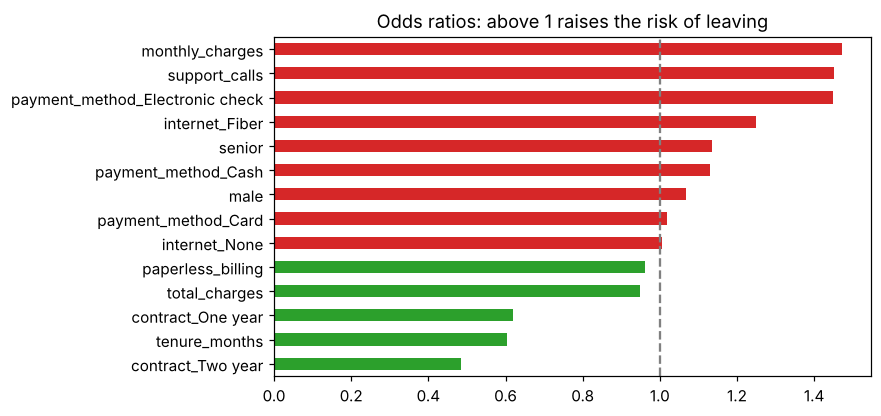

In [10]:
def prepare(df):
    out = df.drop(columns=["customer_id", "churn"]).copy()
    out["internet"] = out["internet"].fillna("None")
    out["total_charges"] = out["total_charges"].fillna(out["tenure_months"] * out["monthly_charges"])
    out["male"] = (out.pop("gender") == "Male").astype(int)
    out = pd.get_dummies(out, columns=["contract", "internet", "payment_method"], drop_first=True)
    return out.astype(float)

X = prepare(churn)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_dev, y_dev)
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.3).astype(int)
print("AUC", round(roc_auc_score(y_test, proba), 3), "recall", round(recall_score(y_test, pred), 2),
      "precision", round(precision_score(y_test, pred), 2))
print(confusion_matrix(y_test, pred))
odds = pd.Series(np.exp(model[-1].coef_[0]), index=X.columns).sort_values()
odds.plot.barh(color=["tab:green" if v < 1 else "tab:red" for v in odds])
plt.axvline(1, color="gray", linestyle="--")
plt.title("Odds ratios: above 1 raises the risk of leaving")
plt.show()

## Part D: Cumulative Project: Apartment Prices

### Exercise 6: Milestone 6: Model Card, Recommendation and Submission

In [11]:
card = '''
Model card: customer churn
Purpose: rank customers by their risk of leaving, to plan retention calls.
Data: 2,000 practice customers, 10 input columns, 30 percent churn.
Model: logistic regression with scaling in one pipeline; text columns one-hot encoded.
Performance (test set, used once): AUC 0.80; at threshold 0.3 recall 0.78 and precision 0.53.
Main drivers: month-to-month contract, short tenure, high monthly charges, many support calls.
Limits: practice data; associations, not causes; check and retrain every few months.

Recommendation
Call customers with a risk of 0.3 or more: this finds about 4 in 5 future leavers,
and about every second call reaches a customer who would really leave.
Prioritise new customers on monthly contracts with high bills, and offer them a move to a yearly contract.
Review customers with repeated support calls quickly, since each call raises the risk.
'''
print(card)


Model card: customer churn
Purpose: rank customers by their risk of leaving, to plan retention calls.
Data: 2,000 practice customers, 10 input columns, 30 percent churn.
Model: logistic regression with scaling in one pipeline; text columns one-hot encoded.
Performance (test set, used once): AUC 0.80; at threshold 0.3 recall 0.78 and precision 0.53.
Main drivers: month-to-month contract, short tenure, high monthly charges, many support calls.
Limits: practice data; associations, not causes; check and retrain every few months.

Recommendation
Call customers with a risk of 0.3 or more: this finds about 4 in 5 future leavers,
and about every second call reaches a customer who would really leave.
Prioritise new customers on monthly contracts with high bills, and offer them a move to a yearly contract.
Review customers with repeated support calls quickly, since each call raises the risk.



## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Everything else uses cross-validation. |
| 2 | B | Cross-validated predictions. |
| 3 | B | The two estimates agree. |
| 4 | B | Scaling on all the data would leak information from the validation folds. |
| 5 | B | Translate metrics into the decision. |